# AgroLab — análisis de resultados

Cuaderno del rol de **Analista de experimentación y datos**. Lee los CSV versionados en
`experiments/` y produce las tablas (`analysis/tablas/`) y figuras (`analysis/figuras/`)
del informe. Se ejecuta de punta a punta con:

```
jupyter nbconvert --to notebook --execute --inplace analysis/analisis.ipynb
```

Convenciones: cada configuración real tiene 5 repeticiones (semillas 1000–1004, las mismas en
todas las configuraciones: números aleatorios comunes). Se informa media, desvío estándar e
intervalo de confianza del 95 % con la distribución t de Student (Jain, 1991, cap. 13).

In [1]:
import json, pathlib, tomllib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "analysis":
    ROOT = ROOT.parent
EXP = ROOT / "experiments"
FIG = ROOT / "analysis" / "figuras"
TAB = ROOT / "analysis" / "tablas"
FIG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

params = tomllib.loads((EXP / "params.toml").read_text(encoding="utf-8"))
cal = json.loads((EXP / "calibration" / "calibration.json").read_text(encoding="utf-8"))

STRATS = ["rr", "ll", "ws"]
NAME = {"rr": "Round Robin", "ll": "Menos cargado", "ws": "Robo de trabajo"}
COLOR = {"rr": "#2a78d6", "ll": "#eb6834", "ws": "#1baf7a"}   # orden categórico fijo
HET = {"H0": "Homogéneo (60/60/60 %)", "H1": "Heterogéneo (100/50/30 %)"}
LATS = params["design"]["latencies_ms"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3de"

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 220, "savefig.bbox": "tight",
})
coma = FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))

def guardar(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", facecolor="white")

def ic95(x):
    x = np.asarray(x, dtype=float)
    return stats.t.ppf(0.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan

def fmt(v, d=2):
    return f"{v:.{d}f}".replace(".", ",")

## 1. Calibración (paso 6)

In [2]:
vel = pd.DataFrame(cal["worker_speed"]).T
vel.index.name = "nivel"
vel["coord"] = cal["coord_speed"]
print("Velocidad medida (unidades de trabajo por segundo; 1 u = SHA-256 de 32 KiB)")
display(vel.round(0))
ref = vel.loc["REF", ["w1", "w2", "w3"]]
rel = vel.loc[["H0", "H1"], ["w1", "w2", "w3"]].div(ref) * 100
print("Velocidad relativa a la misma VM sin límite (%)")
display(rel.round(1))
vel.round(1).to_csv(TAB / "calibracion_cpu.csv")

red = pd.DataFrame(cal["network"]).T
red.index.name = "netem_ms"
red["latency_ms"] = red["latency_s"] * 1000
red["bandwidth_MBps"] = red["bandwidth_Bps"] / 1e6
display(red[["latency_ms", "bandwidth_MBps", "r2"]].round(3))
red[["latency_ms", "bandwidth_MBps", "r2"]].round(4).to_csv(TAB / "calibracion_red.csv")
print(f"Costo del coordinador por mensaje: {cal['coord_msg_cost_s'] * 1e6:.0f} µs")
print(f"Decisión de Menos cargado: {cal['ll_decision']['base_s'] * 1e6:.2f} µs + "
      f"{cal['ll_decision']['per_worker_s'] * 1e9:.1f} ns por trabajador (r² = {cal['ll_decision']['r2']:.3f})")

Velocidad medida (unidades de trabajo por segundo; 1 u = SHA-256 de 32 KiB)


,w1,w2,w3,coord
nivel,,,,
REF,54177.0,52584.0,53980.0,52477.0
H0,32638.0,33507.0,33240.0,52477.0
H1,54153.0,27835.0,16220.0,52477.0


Velocidad relativa a la misma VM sin límite (%)


,w1,w2,w3
nivel,,,
H0,60.2,63.7,61.6
H1,100.0,52.9,30.0


,latency_ms,bandwidth_MBps,r2
netem_ms,,,
0,1.525,34.078,0.958
1,3.467,15.959,0.960
20,38.357,1.620,0.914
100,155.235,0.466,0.919


Costo del coordinador por mensaje: 219 µs
Decisión de Menos cargado: -2.48 µs + 82.8 ns por trabajador (r² = 0.991)


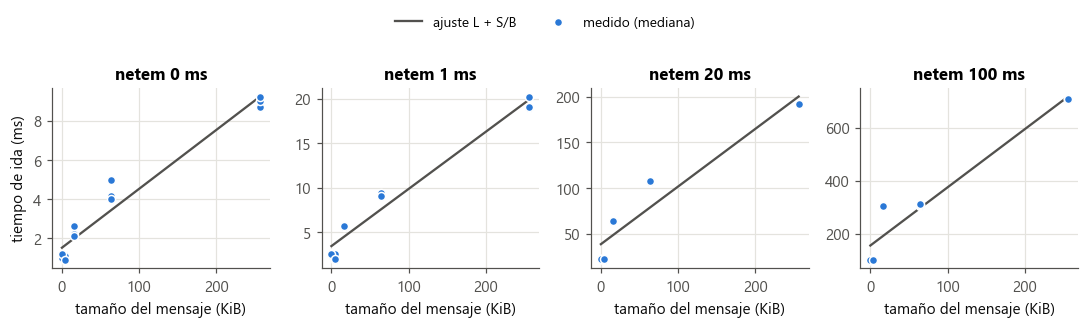

In [3]:
net = pd.read_csv(EXP / "calibration" / "network.csv")
base = net[net["size"] == 0].groupby(["netem_ms", "worker"])["rtt_s"].median() / 2
med = net.groupby(["netem_ms", "worker", "size"])["rtt_s"].median().reset_index()
med["ida_ms"] = (med["rtt_s"] - med.set_index(["netem_ms", "worker"]).index.map(base)) * 1000
fig, axes = plt.subplots(1, len(red), figsize=(10, 3), sharey=False)
for ax, (lat, g) in zip(axes, med.groupby("netem_ms")):
    fit = cal["network"][str(lat)]
    xs = np.linspace(0, g["size"].max(), 50)
    ax.plot(xs / 1024, (fit["latency_s"] + xs / fit["bandwidth_Bps"]) * 1000, color=INK2, lw=1.5, label="ajuste L + S/B")
    ax.scatter(g["size"] / 1024, g["ida_ms"], s=28, color="#2a78d6", edgecolor="white", linewidth=1, zorder=3, label="medido (mediana)")
    ax.set_title(f"netem {lat} ms")
    ax.set_xlabel("tamaño del mensaje (KiB)")
    ax.yaxis.set_major_formatter(coma)
axes[0].set_ylabel("tiempo de ida (ms)")
h, l = axes[0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 1, 0.86))
fig.legend(h, l, loc="upper center", ncols=2, fontsize=9, bbox_to_anchor=(0.5, 1.0))
guardar(fig, "fig_calibracion_red")

## 2. Resultados en el clúster real (paso 5)

In [4]:
runs = pd.read_csv(EXP / "results" / "real" / "runs.csv")
METRICS = {
    "makespan_s": ("Makespan (s)", 2),
    "throughput_tps": ("Rendimiento (tareas/s)", 3),
    "mean_wait_s": ("Espera media (s)", 2),
    "cv_busy": ("Desbalance (CV de ocupación)", 3),
    "msgs_control": ("Mensajes de control", 0),
}
print(f"{len(runs)} corridas; código {runs['code'].unique()}; RTT medido por bloque (ms):")
display(runs.groupby(["latency_ms", "hetero"])["rtt_ms"].first().round(2).unstack())

g = runs.groupby(["hetero", "latency_ms", "strategy"])
resumen = g[list(METRICS)].agg(["mean", "std", ic95, "count"])
resumen.columns = [f"{m}_{s}" for m, s in resumen.columns]
resumen = resumen.reset_index()
resumen.to_csv(TAB / "real_resumen.csv", index=False)

tabla = resumen[["hetero", "latency_ms", "strategy"]].copy()
tabla["strategy"] = tabla["strategy"].map(NAME)
for m, (label, d) in METRICS.items():
    tabla[label] = [f"{fmt(a, d)} ± {fmt(b, d)}" for a, b in zip(resumen[f"{m}_mean"], resumen[f"{m}_std"])]
tabla.columns = ["Heterogeneidad", "Latencia (ms)", "Estrategia", *[v[0] for v in METRICS.values()]]
tabla.to_csv(TAB / "tabla_real.csv", index=False)
display(tabla)

90 corridas; código ['dd84eba7d66b']; RTT medido por bloque (ms):


hetero,H0,H1
latency_ms,,
1,4.61,4.97
20,42.65,43.00
100,202.69,202.84


,Heterogeneidad,Latencia (ms),Estrategia,Makespan (s),Rendimiento (tareas/s),Espera media (s),Desbalance (CV de ocupación),Mensajes de control
0,H0,1,Menos cargado,"39,38 ± 2,38","2,445 ± 0,151","1,43 ± 0,22","0,156 ± 0,032",96 ± 0
1,H0,1,Round Robin,"39,15 ± 3,31","2,465 ± 0,194","1,60 ± 0,17","0,131 ± 0,025",96 ± 0
2,H0,1,Robo de trabajo,"37,43 ± 1,30","2,567 ± 0,089","0,90 ± 0,15","0,058 ± 0,024",394 ± 50
3,H0,20,Menos cargado,"38,94 ± 2,00","2,471 ± 0,128","1,49 ± 0,15","0,107 ± 0,069",96 ± 0
4,H0,20,Round Robin,"39,21 ± 3,16","2,461 ± 0,185","1,68 ± 0,18","0,134 ± 0,020",96 ± 0
5,H0,20,Robo de trabajo,"37,34 ± 1,10","2,573 ± 0,076","1,14 ± 0,24","0,073 ± 0,023",363 ± 57
6,H0,100,Menos cargado,"38,85 ± 1,30","2,473 ± 0,084","2,05 ± 0,09","0,088 ± 0,048",96 ± 0
7,H0,100,Round Robin,"39,87 ± 3,25","2,420 ± 0,185","2,22 ± 0,18","0,134 ± 0,019",96 ± 0
8,H0,100,Robo de trabajo,"38,67 ± 2,02","2,488 ± 0,127","1,98 ± 0,29","0,044 ± 0,034",255 ± 30
9,H1,1,Menos cargado,"42,64 ± 4,96","2,276 ± 0,266","2,36 ± 0,54","0,189 ± 0,054",96 ± 0


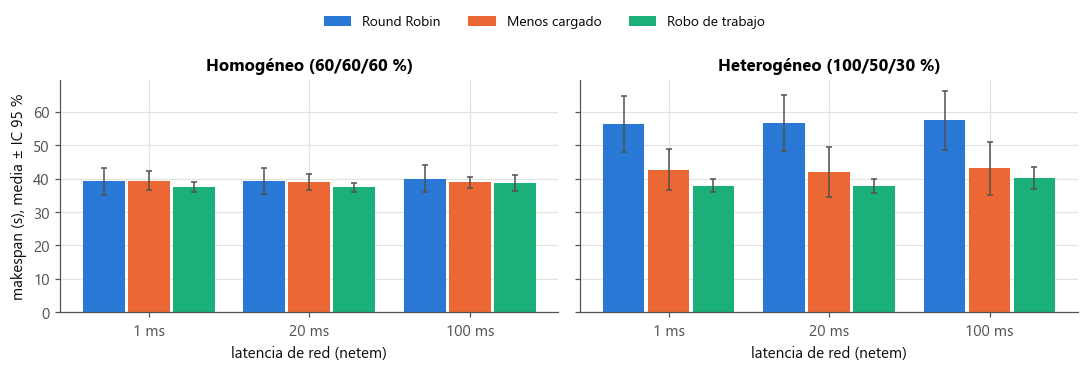

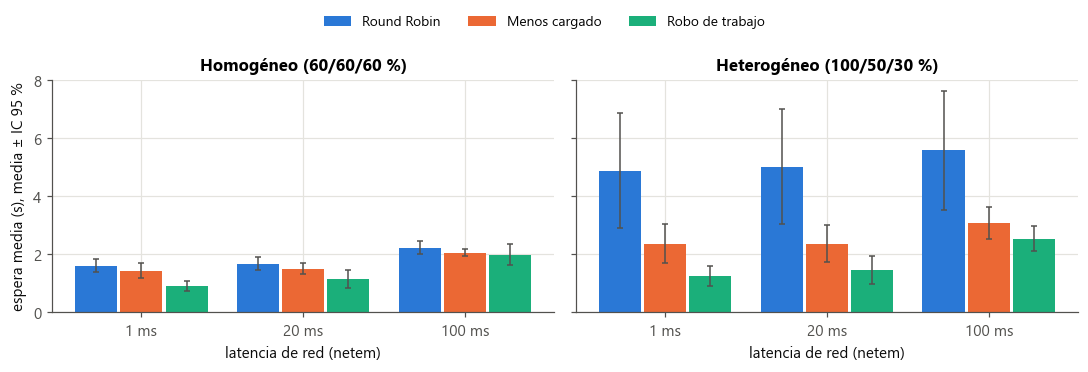

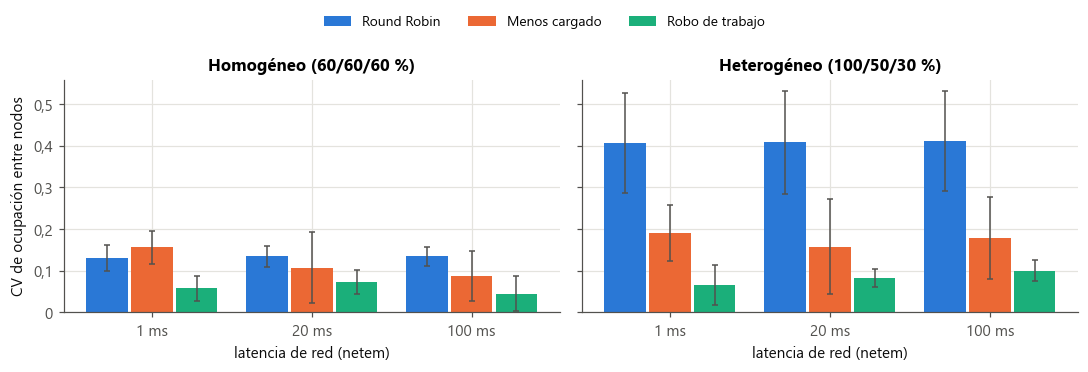

In [5]:
def barras(metric, ylabel, nombre, df=resumen, ic=True):
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
    w = 0.26
    for ax, h in zip(axes, ["H0", "H1"]):
        d = df[df["hetero"] == h]
        for k, s in enumerate(STRATS):
            ds = d[d["strategy"] == s].set_index("latency_ms").reindex(LATS)
            x = np.arange(len(LATS)) + (k - 1) * (w + 0.02)
            err = ds[f"{metric}_ic95"] if ic else None
            ax.bar(x, ds[f"{metric}_mean"], width=w, color=COLOR[s], label=NAME[s], yerr=err,
                   error_kw={"ecolor": INK2, "elinewidth": 1, "capsize": 2})
        ax.set_xticks(np.arange(len(LATS)), [f"{l} ms" for l in LATS])
        ax.set_title(HET[h])
        ax.set_xlabel("latencia de red (netem)")
        ax.yaxis.set_major_formatter(coma)
    axes[0].set_ylabel(ylabel)
    h, l = axes[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0, 1, 0.9))
    fig.legend(h, l, loc="upper center", ncols=3, fontsize=9, bbox_to_anchor=(0.5, 1.0))
    guardar(fig, nombre)
    return fig

barras("makespan_s", "makespan (s), media ± IC 95 %", "fig_real_makespan");
barras("mean_wait_s", "espera media (s), media ± IC 95 %", "fig_real_espera");
barras("cv_busy", "CV de ocupación entre nodos", "fig_real_desbalance");

In [6]:
# Prueba de diferencias entre estrategias en cada configuración (ANOVA de un factor
# sobre el makespan; con 5 repeticiones por grupo).
filas = []
for (h, lat), d in runs.groupby(["hetero", "latency_ms"]):
    grupos = [d.loc[d["strategy"] == s, "makespan_s"] for s in STRATS]
    f, p = stats.f_oneway(*grupos)
    medias = {s: x.mean() for s, x in zip(STRATS, grupos)}
    mejor = min(medias, key=medias.get)
    filas.append({"Heterogeneidad": h, "Latencia (ms)": lat, "F": round(f, 2), "p": p,
                  "Mejor estrategia": NAME[mejor]})
anova = pd.DataFrame(filas)
anova.to_csv(TAB / "real_anova.csv", index=False)
display(anova)

,Heterogeneidad,Latencia (ms),F,p,Mejor estrategia
0,H0,1,0.93,0.421394,Robo de trabajo
1,H0,20,1.01,0.392949,Robo de trabajo
2,H0,100,0.38,0.690290,Robo de trabajo
3,H1,1,19.15,0.000185,Robo de trabajo
4,H1,20,17.48,0.000279,Robo de trabajo
5,H1,100,13.28,0.000908,Robo de trabajo


## 3. Validación del simulador

In [7]:
val = pd.read_csv(EXP / "results" / "sim" / "validation.csv")
sim = val.groupby(["hetero", "latency_ms", "strategy"])[list(METRICS)].mean().reset_index()
comp = resumen.merge(sim, on=["hetero", "latency_ms", "strategy"], suffixes=("", "_sim"))
for m in ["makespan_s", "mean_wait_s", "throughput_tps", "cv_busy"]:
    comp[f"err_{m}"] = (comp[m] - comp[f"{m}_mean"]).abs() / comp[f"{m}_mean"]
cols = ["hetero", "latency_ms", "strategy", "makespan_s_mean", "makespan_s", "err_makespan_s",
        "mean_wait_s_mean", "mean_wait_s", "err_mean_wait_s", "throughput_tps_mean", "throughput_tps",
        "err_throughput_tps", "cv_busy_mean", "cv_busy", "err_cv_busy"]
comp[cols].to_csv(TAB / "validacion.csv", index=False)
v = comp[["hetero", "latency_ms", "strategy"]].copy()
v["strategy"] = v["strategy"].map(NAME)
v["Makespan real (s)"] = comp["makespan_s_mean"].map(fmt)
v["Makespan simulado (s)"] = comp["makespan_s"].map(fmt)
v["Error makespan (%)"] = (comp["err_makespan_s"] * 100).map(lambda x: fmt(x, 1))
v["Espera real (s)"] = comp["mean_wait_s_mean"].map(fmt)
v["Espera simulada (s)"] = comp["mean_wait_s"].map(fmt)
v["Error espera (%)"] = (comp["err_mean_wait_s"] * 100).map(lambda x: fmt(x, 1))
v.columns = ["Heterogeneidad", "Latencia (ms)", "Estrategia", *v.columns[3:]]
v.to_csv(TAB / "tabla_validacion.csv", index=False)
display(v)
print("Error relativo del makespan: media {:.1%}, mediana {:.1%}, máximo {:.1%}".format(
    comp["err_makespan_s"].mean(), comp["err_makespan_s"].median(), comp["err_makespan_s"].max()))
print("Error relativo de la espera media: media {:.1%}, máximo {:.1%}".format(
    comp["err_mean_wait_s"].mean(), comp["err_mean_wait_s"].max()))

,Heterogeneidad,Latencia (ms),Estrategia,Makespan real (s),Makespan simulado (s),Error makespan (%),Espera real (s),Espera simulada (s),Error espera (%)
0,H0,1,Menos cargado,"39,38","39,74","0,9","1,43","1,32","8,0"
1,H0,1,Round Robin,"39,15","38,91","0,6","1,60","1,48","7,4"
2,H0,1,Robo de trabajo,"37,43","37,25","0,5","0,90","0,83","7,5"
3,H0,20,Menos cargado,"38,94","38,54","1,0","1,49","1,49","0,1"
4,H0,20,Round Robin,"39,21","39,21","0,0","1,68","1,67","0,5"
5,H0,20,Robo de trabajo,"37,34","37,59","0,7","1,14","1,05","7,6"
6,H0,100,Menos cargado,"38,85","39,46","1,6","2,05","2,21","7,5"
7,H0,100,Round Robin,"39,87","40,05","0,5","2,22","2,28","2,6"
8,H0,100,Robo de trabajo,"38,67","38,83","0,4","1,98","1,95","1,4"
9,H1,1,Menos cargado,"42,64","39,74","6,8","2,36","1,92","18,6"


Error relativo del makespan: media 1.1%, mediana 0.6%, máximo 6.8%
Error relativo de la espera media: media 7.0%, máximo 28.1%


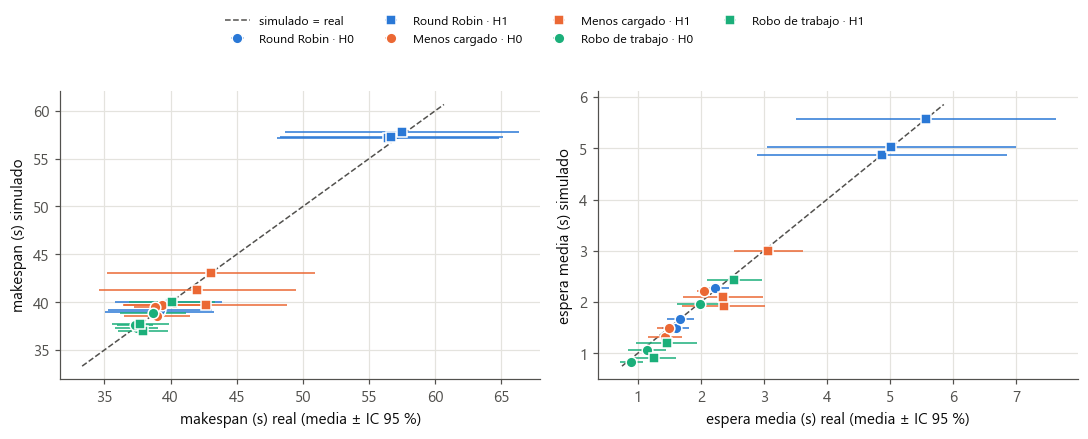

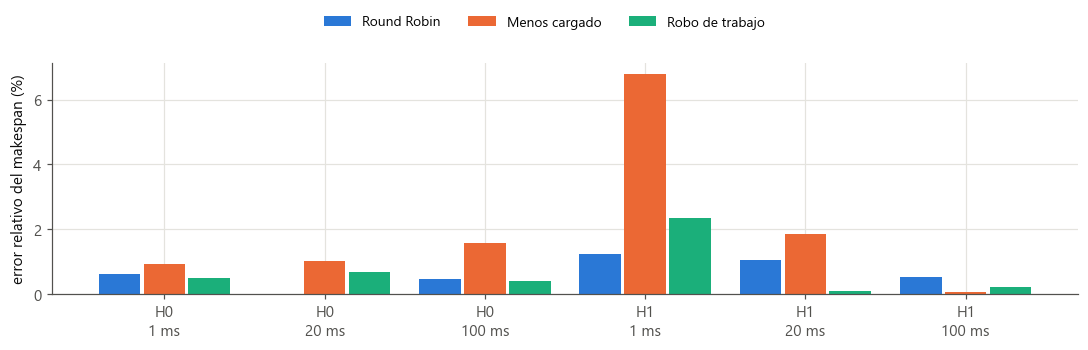

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (m, label) in zip(axes, [("makespan_s", "makespan (s)"), ("mean_wait_s", "espera media (s)")]):
    lo = min(comp[f"{m}_mean"].min(), comp[m].min()) * 0.9
    hi = max(comp[f"{m}_mean"].max(), comp[m].max()) * 1.05
    ax.plot([lo, hi], [lo, hi], color=INK2, lw=1, ls="--", label="simulado = real")
    for s in STRATS:
        for h, marker in [("H0", "o"), ("H1", "s")]:
            d = comp[(comp["strategy"] == s) & (comp["hetero"] == h)]
            ax.errorbar(d[f"{m}_mean"], d[m], xerr=d[f"{m}_ic95"], fmt=marker, ms=7, color=COLOR[s],
                        mec="white", mew=1, ecolor=COLOR[s], elinewidth=1,
                        label=f"{NAME[s]} · {h}")
    ax.set_xlabel(f"{label} real (media ± IC 95 %)")
    ax.set_ylabel(f"{label} simulado")
    ax.xaxis.set_major_formatter(coma); ax.yaxis.set_major_formatter(coma)
h, l = axes[0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 1, 0.84))
fig.legend(h, l, loc="upper center", ncols=4, fontsize=8, bbox_to_anchor=(0.5, 1.0))
guardar(fig, "fig_validacion_dispersion")

fig, ax = plt.subplots(figsize=(10, 3.2))
w = 0.26
etiquetas = []
for i, (h, lat) in enumerate([(h, l) for h in ["H0", "H1"] for l in LATS]):
    etiquetas.append(f"{h}\n{lat} ms")
    for k, s in enumerate(STRATS):
        e = comp[(comp["hetero"] == h) & (comp["latency_ms"] == lat) & (comp["strategy"] == s)]["err_makespan_s"]
        ax.bar(i + (k - 1) * (w + 0.02), e.iloc[0] * 100, width=w, color=COLOR[s], label=NAME[s] if i == 0 else None)
ax.set_xticks(range(len(etiquetas)), etiquetas)
ax.set_ylabel("error relativo del makespan (%)")
ax.yaxis.set_major_formatter(coma)
h, l = ax.get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.legend(h, l, loc="upper center", ncols=3, fontsize=9, bbox_to_anchor=(0.5, 1.0))
guardar(fig, "fig_validacion_error")

In [9]:
# ¿El simulador conserva el orden de las estrategias? (lo que importa para decidir)
filas = []
for (h, lat), d in comp.groupby(["hetero", "latency_ms"]):
    real = list(d.sort_values("makespan_s_mean")["strategy"])
    simu = list(d.sort_values("makespan_s")["strategy"])
    tau = stats.kendalltau([real.index(s) for s in STRATS], [simu.index(s) for s in STRATS]).statistic
    filas.append({"Heterogeneidad": h, "Latencia (ms)": lat,
                  "Orden real": " < ".join(NAME[s] for s in real),
                  "Orden simulado": " < ".join(NAME[s] for s in simu),
                  "Misma mejor": real[0] == simu[0], "tau de Kendall": round(tau, 2)})
ranking = pd.DataFrame(filas)
ranking.to_csv(TAB / "validacion_ranking.csv", index=False)
display(ranking)

,Heterogeneidad,Latencia (ms),Orden real,Orden simulado,Misma mejor,tau de Kendall
0,H0,1,Robo de trabajo < Round Robin < Menos cargado,Robo de trabajo < Round Robin < Menos cargado,True,1.0
1,H0,20,Robo de trabajo < Menos cargado < Round Robin,Robo de trabajo < Menos cargado < Round Robin,True,1.0
2,H0,100,Robo de trabajo < Menos cargado < Round Robin,Robo de trabajo < Menos cargado < Round Robin,True,1.0
3,H1,1,Robo de trabajo < Menos cargado < Round Robin,Robo de trabajo < Menos cargado < Round Robin,True,1.0
4,H1,20,Robo de trabajo < Menos cargado < Round Robin,Robo de trabajo < Menos cargado < Round Robin,True,1.0
5,H1,100,Robo de trabajo < Menos cargado < Round Robin,Robo de trabajo < Menos cargado < Round Robin,True,1.0


## 4. Extrapolación por simulación (paso 7)

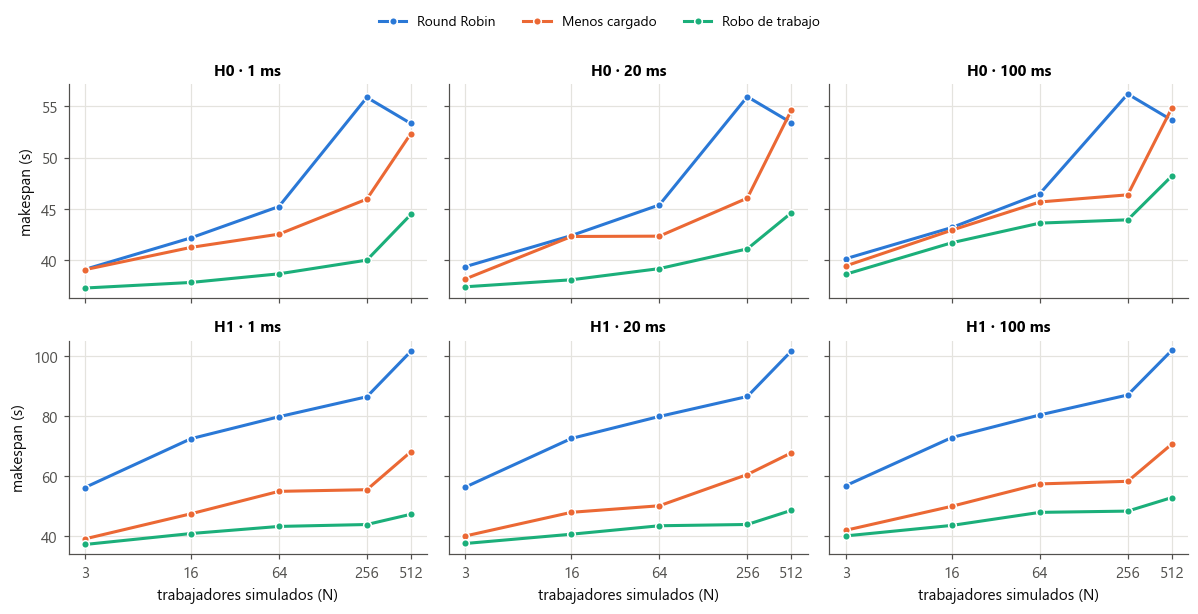

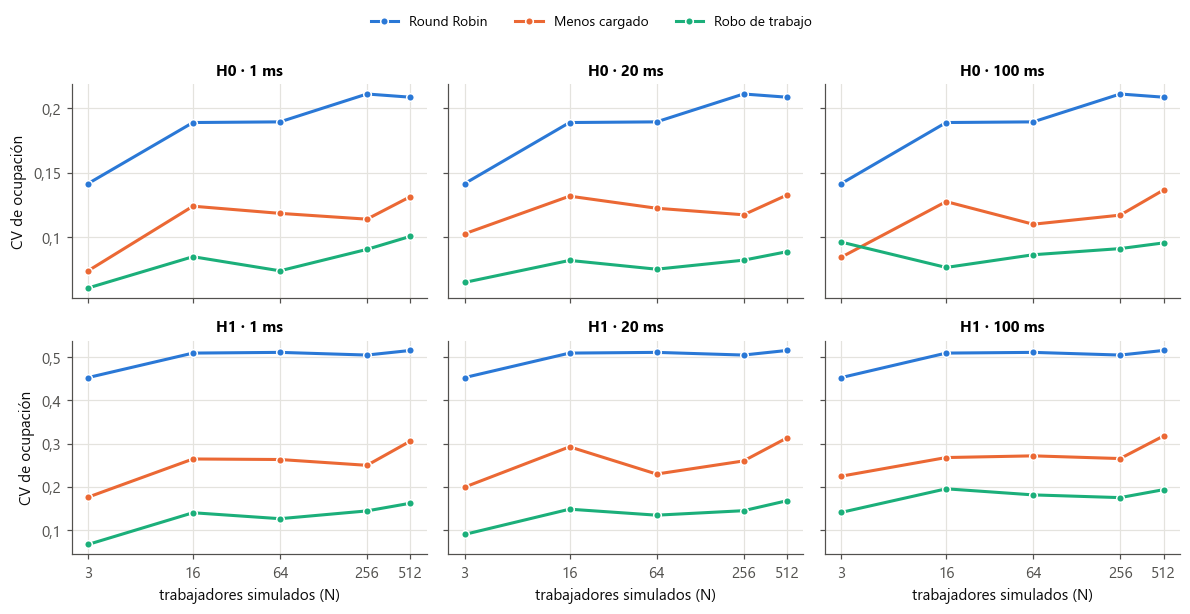

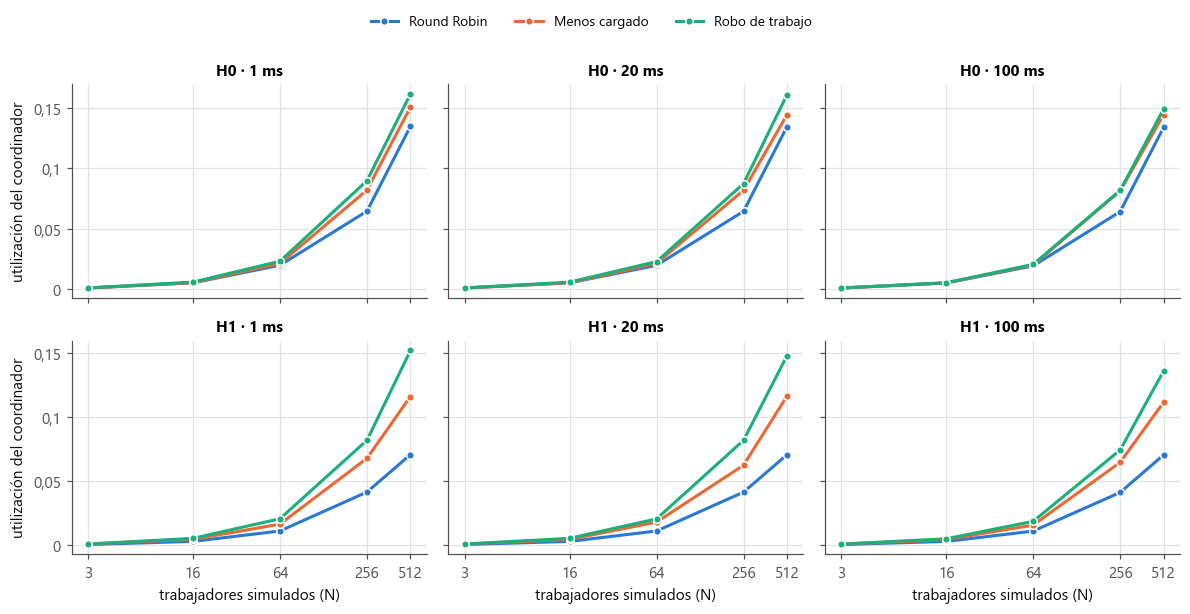

In [10]:
scale = pd.read_csv(EXP / "results" / "sim" / "scale.csv")
sc = scale.groupby(["n_workers", "hetero", "latency_ms", "strategy"]).agg(
    makespan=("makespan_s", "mean"), espera=("mean_wait_s", "mean"), cv=("cv_busy", "mean"),
    coord=("coord_util", "mean"), tareas=("tasks", "first"), sim_s=("sim_wall_s", "mean")).reset_index()
sc.to_csv(TAB / "escala_resumen.csv", index=False)
NS = sorted(sc["n_workers"].unique())

def curvas(col, ylabel, nombre, logy=False):
    fig, axes = plt.subplots(2, len(LATS), figsize=(11, 5.6), sharex=True, sharey="row" if not logy else False)
    for i, h in enumerate(["H0", "H1"]):
        for j, lat in enumerate(LATS):
            ax = axes[i, j]
            for s in STRATS:
                d = sc[(sc["hetero"] == h) & (sc["latency_ms"] == lat) & (sc["strategy"] == s)].sort_values("n_workers")
                ax.plot(d["n_workers"], d[col], color=COLOR[s], lw=2, marker="o", ms=5, mec="white", mew=1, label=NAME[s])
            ax.set_xscale("log", base=2)
            ax.set_xticks(NS, [str(n) for n in NS])
            if logy:
                ax.set_yscale("log")
            ax.yaxis.set_major_formatter(coma)
            ax.set_title(f"{h} · {lat} ms", fontsize=10)
            if i == 1:
                ax.set_xlabel("trabajadores simulados (N)")
        axes[i, 0].set_ylabel(ylabel)
    h, l = axes[0, 0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0, 1, 0.93))
    fig.legend(h, l, loc="upper center", ncols=3, fontsize=9, bbox_to_anchor=(0.5, 1.0))
    guardar(fig, nombre)

curvas("makespan", "makespan (s)", "fig_escala_makespan")
curvas("cv", "CV de ocupación", "fig_escala_desbalance")
curvas("coord", "utilización del coordinador", "fig_escala_coordinador")

In [11]:
# Ranking de estrategias en cada escala
filas = []
for (n, h, lat), d in sc.groupby(["n_workers", "hetero", "latency_ms"]):
    orden = list(d.sort_values("makespan")["strategy"])
    filas.append({"N": n, "Heterogeneidad": h, "Latencia (ms)": lat, "Mejor": NAME[orden[0]],
                  "Orden": " < ".join(NAME[s] for s in orden)})
rank_esc = pd.DataFrame(filas)
rank_esc.to_csv(TAB / "escala_ranking.csv", index=False)
display(rank_esc.pivot_table(index=["Heterogeneidad", "Latencia (ms)"], columns="N", values="Mejor", aggfunc="first"))

N                                         3                16   \
Heterogeneidad Latencia (ms)                                     
H0             1              Robo de trabajo  Robo de trabajo   
               20             Robo de trabajo  Robo de trabajo   
               100            Robo de trabajo  Robo de trabajo   
H1             1              Robo de trabajo  Robo de trabajo   
               20             Robo de trabajo  Robo de trabajo   
               100            Robo de trabajo  Robo de trabajo   

N                                         64               256  \
Heterogeneidad Latencia (ms)                                     
H0             1              Robo de trabajo  Robo de trabajo   
               20             Robo de trabajo  Robo de trabajo   
               100            Robo de trabajo  Robo de trabajo   
H1             1              Robo de trabajo  Robo de trabajo   
               20             Robo de trabajo  Robo de trabajo   
               100            Robo de trabajo  Robo de trabajo   

N                                         512  
Heterogeneidad Latencia (ms)                   
H0             1              Robo de trabajo  
               20             Robo de trabajo  
               100            Robo de trabajo  
H1             1              Robo de trabajo  
               20             Robo de trabajo  
               100            Robo de trabajo

### El límite del coordinador

Todas las tareas salen del coordinador con sus datos. Si en cada período llega un lote de 8N/3 tareas,
el enlace del coordinador tiene que transmitir 8N/3 × (encabezado + datos medios) bytes cada 3 s; cuando
esa demanda supera la capacidad medida del enlace, los lotes empiezan a encolarse.

Saturación del enlace del coordinador: N ≈ 492 trabajadores
Saturación de la CPU del coordinador (2 mensajes × 219 µs por tarea): N ≈ 2564


hetero       H0                 H1             
strategy     ll    rr    ws     ll     rr    ws
n_workers                                      
3          38.2  39.4  37.4   40.0   56.3  37.5
16         42.3  42.4  38.1   47.9   72.6  40.6
64         42.4  45.4  39.2   50.1   79.9  43.4
256        46.1  55.9  41.1   60.5   86.6  43.9
384        48.6  51.1  41.8   58.2   99.0  45.2
512        54.6  53.4  44.6   67.8  101.7  48.6
640        71.0  72.4  61.0  115.1  121.5  62.5
768        85.9  84.1  70.1  115.3  112.0  74.8

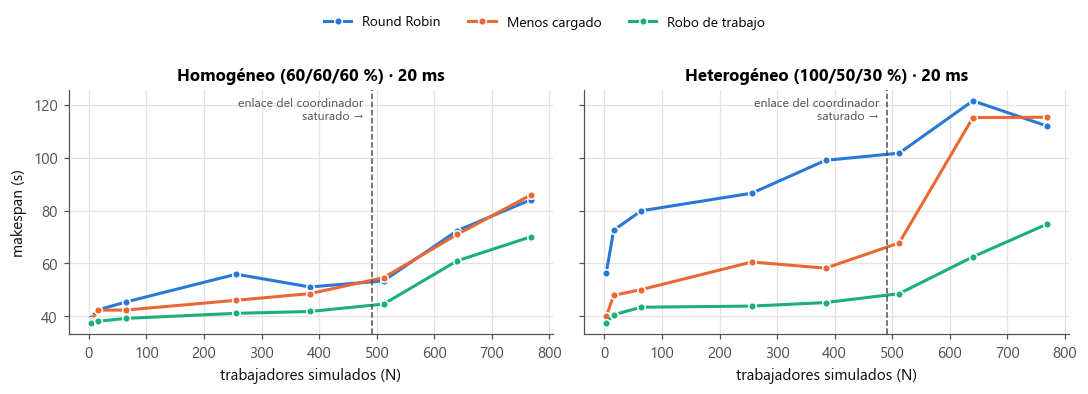

In [12]:
w = params["workload"]
datos_medios = w["heavy_fraction"] * w["heavy_size"] + (1 - w["heavy_fraction"]) * w["light_size"] + 160
cap = cal["network"]["0"]["bandwidth_Bps"]
tpb_por_nodo = w["tasks_per_batch"] / len(params["cluster"]["workers"])
n_red = cap * w["period_s"] / (tpb_por_nodo * datos_medios)
costo_tarea = 2 * cal["coord_msg_cost_s"]
n_cpu = w["period_s"] / (tpb_por_nodo * costo_tarea)
print(f"Saturación del enlace del coordinador: N ≈ {n_red:.0f} trabajadores")
print(f"Saturación de la CPU del coordinador (2 mensajes × {cal['coord_msg_cost_s']*1e6:.0f} µs por tarea): N ≈ {n_cpu:.0f}")
codo_path = EXP / "results" / "sim" / "scale_codo.csv"
todo = pd.concat([scale, pd.read_csv(codo_path)]) if codo_path.exists() else scale
c = todo[todo["latency_ms"] == 20].groupby(["n_workers", "hetero", "strategy"]).agg(
    makespan=("makespan_s", "mean"), coord=("coord_util", "mean")).reset_index()
c.to_csv(TAB / "codo_coordinador.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, h in zip(axes, ["H0", "H1"]):
    for s_ in STRATS:
        d = c[(c["hetero"] == h) & (c["strategy"] == s_)].sort_values("n_workers")
        ax.plot(d["n_workers"], d["makespan"], color=COLOR[s_], lw=2, marker="o", ms=5, mec="white", mew=1, label=NAME[s_])
    ax.axvline(n_red, color=INK2, lw=1, ls="--")
    ax.text(n_red * 0.97, 0.97, "enlace del coordinador\nsaturado →", fontsize=8, color=INK2, va="top", ha="right",
            transform=ax.get_xaxis_transform())
    ax.set_title(f"{HET[h]} · 20 ms")
    ax.set_xlabel("trabajadores simulados (N)")
    ax.yaxis.set_major_formatter(coma)
axes[0].set_ylabel("makespan (s)")
h_, l_ = axes[0].get_legend_handles_labels()
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.legend(h_, l_, loc="upper center", ncols=3, fontsize=9, bbox_to_anchor=(0.5, 1.0))
guardar(fig, "fig_escala_codo")
display(c.pivot_table(index="n_workers", columns=["hetero", "strategy"], values="makespan").round(1))

## 5. Consumo de recursos y costo de simular frente a emular

In [13]:
# El coordinador registra la hora en UTC (zona de las VM).
inicio = pd.to_datetime(runs["started"], utc=True)
real_ini = inicio.min()
real_fin = (inicio + pd.to_timedelta(runs["wall_s"], unit="s")).max()
camp_real = (real_fin - real_ini).total_seconds()
costo = pd.DataFrame([
    {"Qué": "Campaña real (90 corridas, incluye cambios de condiciones)", "Tiempo de reloj (min)": camp_real / 60},
    {"Qué": "Suma de corridas reales", "Tiempo de reloj (min)": runs["wall_s"].sum() / 60},
    {"Qué": "Validación simulada (90 simulaciones)", "Tiempo de reloj (min)": val["sim_wall_s"].sum() / 60},
    {"Qué": "Extrapolación simulada (CPU acumulada)", "Tiempo de reloj (min)": scale["sim_wall_s"].sum() / 60},
])
costo["Tiempo de reloj (min)"] = costo["Tiempo de reloj (min)"].round(2)
costo.to_csv(TAB / "costo_simular_emular.csv", index=False)
display(costo)
print("Tiempo de simulación por corrida según N (s):")
display(sc.groupby("n_workers")["sim_s"].mean().round(2))

host_path = EXP / "results" / "real" / "host.csv"
if host_path.exists():
    host = pd.read_csv(host_path, parse_dates=["timestamp"])
    # El anfitrión registra la hora local de Argentina (UTC−3, sin horario de verano).
    host["timestamp"] = (host["timestamp"] + pd.Timedelta(hours=3)).dt.tz_localize("UTC")
    host = host[(host["timestamp"] >= real_ini) & (host["timestamp"] <= real_fin)]
    display(host[["host_cpu_pct", "host_free_mb", "vbox_cpu_pct", "vbox_mem_mb", "other_cpu_pct"]].describe().round(1))
    host.describe().round(2).to_csv(TAB / "anfitrion.csv")

vm_path = EXP / "results" / "real" / "vm_resources.csv"
if vm_path.exists():
    vm = pd.read_csv(vm_path)
    r = vm.groupby("node")[["cpu_cores", "mem_used_mb", "net_tx_kbps", "net_rx_kbps"]].agg(["mean", "max"]).round(2)
    r.to_csv(TAB / "vm_recursos.csv")
    display(r)

,Qué,Tiempo de reloj (min)
0,"Campaña real (90 corridas, incluye cambios de ...",69.39
1,Suma de corridas reales,63.83
2,Validación simulada (90 simulaciones),0.06
3,Extrapolación simulada (CPU acumulada),35.16


Tiempo de simulación por corrida según N (s):


n_workers
3       0.03
16      0.22
64      1.01
256     6.59
512    31.21
Name: sim_s, dtype: float64

,host_cpu_pct,host_free_mb,vbox_cpu_pct,vbox_mem_mb,other_cpu_pct
count,772.0,772.0,772.0,772.0,772.0
mean,16.6,2185.2,139.9,3276.4,5.6
std,7.3,353.9,42.5,90.4,5.9
min,0.0,1201.0,23.0,2712.0,0.0
25%,12.0,1841.5,114.2,3292.0,0.0
50%,17.0,2311.0,149.0,3310.0,4.0
75%,21.0,2400.0,172.4,3315.0,8.0
max,48.0,3158.0,241.5,3335.0,42.0


cpu_cores       mem_used_mb          net_tx_kbps          net_rx_kbps  \
           mean   max        mean      max        mean      max        mean   
node                                                                          
coord      0.00  0.01     1165.96  1319.05     1353.11  2028.59      273.09   
w1         0.41  0.79      182.84   219.70      113.44   463.45      554.66   
w2         0.36  0.55      176.21   210.50      117.03   364.42      458.51   
w3         0.33  0.56      174.19   208.71      136.15   570.45      422.97   

                
           max  
node            
coord   284.08  
w1     1122.09  
w2      871.41  
w3      841.99